In [2]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


import matplotlib.pyplot as plt
dst = pd.read_csv('../datasets/data.csv')

count    4.757000e+03
mean     1.834339e+07
std      9.819188e+07
min      1.000000e+03
25%      1.000000e+06
50%      5.000000e+06
75%      1.640000e+07
max      5.700000e+09
Name: funding_total_usd, dtype: float64


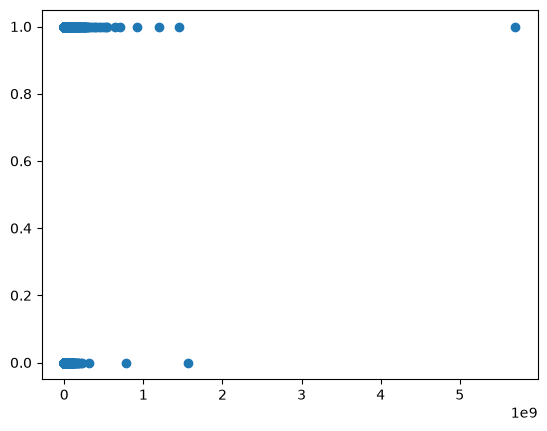

In [3]:
# print(dst["funding_total_usd"][dst["funding_total_usd"]>1000000000].index)
# dst["funding_total_usd"] = dst["funding_total_usd"].drop(index=dst["funding_total_usd"][dst["funding_total_usd"]>100000000].index)
print(dst["funding_total_usd"].describe())

plt.scatter(dst["funding_total_usd"], dst["status"])
plt.show()

In [4]:
print(dst["funding_total_usd"].describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]))

print("Minimum funding:", dst["funding_total_usd"].min())
print("Maximum funding:", dst["funding_total_usd"].max())

count    4.757000e+03
mean     1.834339e+07
std      9.819188e+07
min      1.000000e+03
50%      5.000000e+06
75%      1.640000e+07
90%      4.000000e+07
95%      6.500000e+07
99%      1.713345e+08
max      5.700000e+09
Name: funding_total_usd, dtype: float64
Minimum funding: 1000.0
Maximum funding: 5700000000.0


In [5]:
class Model:

    def __init__(self, data, features, target):
        self.data = data.copy()
        self.features = features
        self.target = target

        self.split_data()

        self.model = Pipeline([
            ('log', FunctionTransformer(np.log1p)),
            ('scaler', StandardScaler()),
            ('model', LogisticRegression(max_iter=1000))
        ])


    def split_data(self, test_size=0.2, random_state=42):
        self.X_train, self.X_test, self.y_train, self.y_test = train_test_split(
            self.data[self.features],
            self.data[self.target],
            test_size=test_size,
            random_state=random_state,
            stratify=self.data[self.target]
        )

    def format_data(self, input_data):
        return pd.DataFrame(input_data, columns=self.features)

    def train(self):
        self.model.fit(self.X_train, self.y_train)


    def predict(self, input_data=None):
        if input_data is None:
            input_data = self.X_test
        else:
            input_data = self.format_data(input_data)

        return self.model.predict(input_data)


    def evaluate(self):
        predictions = self.predict()
        print(f'''Model Accuracy: {accuracy_score(self.y_test, predictions)}
Confusion Matrix: \n{confusion_matrix(self.y_test, predictions)}
Classification Report: \n{classification_report(self.y_test, predictions)}''')


    def baseline(self):
        dummy = DummyClassifier(strategy='most_frequent')
        dummy.fit(self.X_train, self.y_train)
        return dummy.score(self.X_test, self.y_test)


    def cross_validate(self, cv=5):
        skf = StratifiedKFold(
            n_splits=cv,
            shuffle=True,
            random_state=42
        )
        scores = cross_val_score(
            self.model,
            self.X_train,
            self.y_train,
            cv=skf,
            scoring='accuracy'
        )
        return {
            'scores': scores,
            'mean': scores.mean(),
            'std': scores.std()
        }


In [6]:
dst = pd.read_csv('../datasets/data.csv')

startupPredictor = Model(
    dst,
    ['funding_total_usd'],
    'status'
)

# Train
startupPredictor.train()

# Evaluate
startupPredictor.evaluate()

# Baseline comparison
print("\nBaseline Accuracy:", startupPredictor.baseline())

# Cross-validation
cv_results = startupPredictor.cross_validate()

print("\nCross Validation Scores:", cv_results['scores'])
print("Mean CV Accuracy:", cv_results['mean'])
print("Standard Deviation:", cv_results['std'])

Model Accuracy: 0.7394957983193278
Confusion Matrix: 
[[196 166]
 [ 82 508]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.71      0.54      0.61       362
           1       0.75      0.86      0.80       590

    accuracy                           0.74       952
   macro avg       0.73      0.70      0.71       952
weighted avg       0.74      0.74      0.73       952


Baseline Accuracy: 0.6197478991596639

Cross Validation Scores: [0.70959264 0.72667543 0.73193167 0.72010512 0.72536137]
Mean CV Accuracy: 0.7227332457293034
Standard Deviation: 0.007571542859862257


In [7]:
raw_data = [
    [5000000],
    [25000000],
    [100000000]
]

predictions = startupPredictor.predict(raw_data)

print("\nNew Startup Predictions:")
print(predictions)



New Startup Predictions:
[1 1 1]
